# Logistic regression

Logistic regression is a supervised learning algorithm used for binary classification, predicting whether an input belongs to one of two classes. It models the probability of an outcome using a sigmoid function, which maps inputs to a probability between 0 and 1. By adjusting weights through optimization, logistic regression finds the best decision boundary for separating classes.

## Outline
- [1. Introduction](#1-introduction)
- [2. The sigmoid function](#2-the-sigmoid-function)
- [3. Binary cross entropy](#3-binary-cross-entropy)
- [4. Data](#4-data)
- [5. Gradient Computation for Logistic Regression with Binary Cross-Entropy Loss](#5-gradient-computation-for-logistic-regression-with-binary-cross-entropy-loss)
- [6. Logistic regression implementation](#6-logistic-regression-implementation)
- [7. Example usage](#7-example-usage)
- [8. Testing on 2D data](#8-testing-on-2d-data)
- [9. Ideas to Deepen Your Knowledge](#9-ideas-to-deepen-your-knowledge)


## 1. Introduction
This Jupyter notebook implements logistic regression optimizing binary cross entropy loss using only the NumPy library (and MatPlotLib for display). It includes all the derivations of equations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=2)

## 2. The sigmoid function

$$
\sigma(z) = \frac{1}{1+e^{-z}}
\\
\sigma'(z) = \sigma(z)(1 - \sigma(z))
$$

In [2]:
def sigma(z):
    """The sigmoid function."""
    return 1 / (1 + np.e**(-1*z))

def d_sigma(z):
    """The derivative of the sigmoid function."""
    return sigma(z) * (1 - sigma(z))

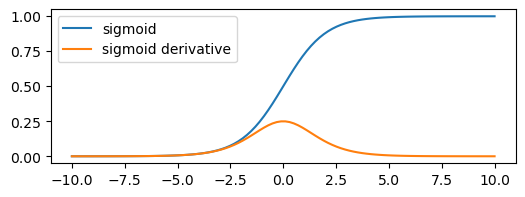

In [3]:
# Plot the sigmoid and its derivative
x = np.linspace(-10, 10, 100)
y1 = sigma(x)
y2 = d_sigma(x)

# set figure size
plt.figure(figsize=(6, 2))
plt.plot(x, y1, label='sigmoid')
plt.plot(x, y2, label='sigmoid derivative')
plt.legend()
plt.show()

## 3. Binary cross entropy
The BCE loss for a single example $i$ is:

$$
L = \text{Binary Cross Entropy}(y^{(i)}, \hat{y}^{(i)}) = -\left( y \cdot \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \cdot \log(1 - \hat{y}^{(i)}) \right)
$$

For a batch of $m$ examples, the average BCE loss is:

$$
L = \text{Binary Cross Entropy}(y, \hat{y}) = - \frac{1}{m}\sum\left( y \cdot \log(\hat{y}) + (1 - y) \cdot \log(1 - \hat{y}) \right)
$$

To perform backpropagation, we need to compute the partial derivative of the loss $L$ with respect to the predicted output $\hat{y}^{(i)}$ for each example $i$:

$$
\frac{\partial L}{\partial \hat{y}^{(i)}} = 
- \frac{1}{m} \left( \frac{y^{(i)}}{\hat{y}^{(i)}} + \frac{1 - y^{(i)}}{1 - \hat{y}^{(i)}}  \right)
$$

In [4]:
# Binary cross entropy
# import numpy as np

def binary_cross_entropy(y, y_hat):
    """Compute the binary cross entropy loss.
    
    Parameters:
    y (array-like): Binary vector of true labels (0 or 1).
    y_hat (array-like): Vector of predicted probabilities.

    Returns:
    float: Binary cross entropy loss.
    """
    y = np.array(y)
    y_hat = np.array(y_hat)
    y_hat = np.clip(y_hat, 1e-15, 1 - 1e-15)     # to avoid log(0)
    return -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

def binary_cross_entropy_derivative(y, y_hat):
    """Compute the binary cross entropy loss derivative w.e.t. y_hat.
    
    Parameters:
    y (array-like): Binary vector of true labels (0 or 1).
    y_hat (array-like): Vector of predicted probabilities.

    Returns:
    array-like: Binary cross entropy loss derivative.
    """
    y = np.array(y)
    y_hat = np.array(y_hat)
    m = y.shape[0]
    return -((y - y_hat) / (y_hat * (1 - y_hat)))


In [5]:
y = [0, 0, 0, 0, 1, 1, 1, 1]
y_pred = [0.01, 0.0001, 0.2, 0.3, 0.9, 0.99, 0.9988, 0.99999]    # because of the sigmoid function, the values are in the interval (0, 1): never 0 or 1

print(binary_cross_entropy(y, y_pred))
binary_cross_entropy_derivative(y, y_pred)


0.08832380103057799


array([ 1.01,  1.  ,  1.25,  1.43, -1.11, -1.01, -1.  , -1.  ])

## 4. Data
We have some artificial data with one input: the person's weight, and one output: whether they are obese or not.

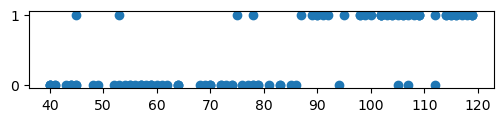

In [6]:
# Data

# weight in kgs
x = [40, 40, 40, 40, 41, 41, 43, 44, 44, 44, 45, 45, 45, 48, 49, 52, 53, 53, 54, 55, 55, 56, 57, 57, 57, 58, 59, 59, 59, 60, 61, 62, 64, 64, 64, 68, 69, 70, 70, 70, 72, 72, 73, 74, 74, 75, 76, 77, 78, 78, 78, 79, 79, 81, 83, 83, 85, 86, 87, 89, 90, 90, 91, 92, 94, 95, 98, 98, 99, 100, 102, 102, 102, 102, 103, 104, 104, 105, 105, 106, 106, 107, 107, 108, 109, 109, 109, 112, 112, 114, 114, 115, 115, 116, 116, 117, 118, 119, 119, 119]
# obese yes or no
y = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

# Make the data numpy column arrays
x = np.array(x).reshape(-1, 1)
y = np.array(y).reshape(-1, 1)

# scatter plot
plt.figure(figsize=(6, 1))
plt.scatter(x, y)


In [7]:
class MinMaxScaler:
    def __init__(self):
        self.X_min = None
        self.X_max = None

    def fit(self, X):
        self.X_min = X.min(axis=0)     # learn the scaling parameters (from training data)
        self.X_max = X.max(axis=0)

    def transform(self, X):            # apply the scaling
        return 2 * (X - self.X_min) / (self.X_max - self.X_min) - 1
    
    def inverse_transform(self, X):    # reverse the scaling
        return (X + 1) * (self.X_max - self.X_min) / 2 + self.X_min
    


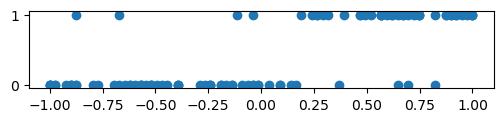

In [8]:
# Use the MinMaxScaler to scale the data in the range [-1, 1]

mm_scaler = MinMaxScaler()
mm_scaler.fit(x)                  # learn the scaling parameters
x = mm_scaler.transform(x)        # apply the scaling

# scatter plot
plt.figure(figsize=(6, 1))
plt.scatter(x, y)

## 5. Gradient Computation for Logistic Regression with Binary Cross-Entropy Loss

Step-by-step gradient computation for logistic regression with two input features and binary cross-entropy loss.

### 5.1  Notation
- $ x^{(i)} = [x_1^{(i)}, x_2^{(i)}] $ be the input vector for the $ i $-th example, where $ x_1^{(i)} $ and $ x_2^{(i)} $ are the two features.
- $ w = [w_1, w_2]^T $ is a column vector of the weights corresponding to each feature.
- $ b $ is the bias term.
- $ z^{(i)} $ is the weighted linear input for the $ i $-th example.
- $ \hat{y}^{(i)} $ is the predicted output for the $ i $-th example after applying the sigmoid function.
- $ y^{(i)} $ is the true label for the $ i $-th example (either 0 or 1).

The weighted input $ z^{(i)} $ and prediction $ \hat{y}^{(i)} $ are computed in the forward pass as:

$$
z^{(i)} = w_1 x_1^{(i)} + w_2 x_2^{(i)} + b
$$

$$
\hat{y}^{(i)} = \sigma(z^{(i)}) = \frac{1}{1 + e^{-z^{(i)}}}
$$

### 5.2 Binary Cross-Entropy Loss
The BCE loss for a single example $ i $ is:

$$
L^{(i)} = -\left( y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right)
$$

For a batch of $ m $ examples, the average BCE loss is:

$$
\begin{aligned}
L &= \frac{1}{m} \sum_{i=1}^{m} L^{(i)} \\
  &= -\frac{1}{m} \sum_{i=1}^{m} \left( y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right)
\end{aligned}
$$

### 5.3 Gradient of the Loss with Respect to the Predicted Output $\hat{y}$
The partial derivative of the loss $ L $ with respect to the predicted output $ \hat{y}^{(i)} $ for each example $ i $:

$$
\frac{\partial L}{\partial \hat{y}^{(i)}} = -\frac{1}{m} \left( \frac{y^{(i)}}{\hat{y}^{(i)}} - \frac{1 - y^{(i)}}{1 - \hat{y}^{(i)}} \right)
$$

### 5.4 Gradient of the Predicted Output with Respect to $ z^{(i)} $
Since $ \hat{y}^{(i)} = \sigma(z^{(i)}) $, we use the derivative of the sigmoid function:

$$
\frac{d \sigma}{d z} = \sigma(z)(1 - \sigma(z))
$$
and get

$$
\frac{\partial \hat{y}^{(i)}}{\partial z^{(i)}} = \hat{y}^{(i)} \cdot (1 - \hat{y}^{(i)})
$$

We apply the chain rule to get  the gradient of the loss $ L $ with respect to $ z^{(i)} $ is:

$$
\begin{aligned}
\frac{\partial L}{\partial z^{(i)}} &= \frac{\partial L}{\partial \hat{y}^{(i)}} \cdot \frac{\partial \hat{y}^{(i)}}{\partial z^{(i)}} \\[10pt]
&= -\frac{1}{m} \left( \frac{y^{(i)}}{\hat{y}^{(i)}} - \frac{1 - y^{(i)}}{1 - \hat{y}^{(i)}} \right) \cdot \hat{y}^{(i)} \cdot (1 - \hat{y}^{(i)}) \\[10pt]
&= -\frac{1}{m} \cdot \left( \hat{y}^{(i)} - y^{(i)} \right)
\end{aligned}
$$

### 5.5 Gradients with Respect to Weights $ w $  and Bias $ b $
The gradients of the loss with respect to the weights $ w_1 $ and $ w_2 $, and the bias $ b $ 

- Gradient with respect to $ w_1 $:

$$
\begin{aligned}
\frac{\partial L}{\partial w_1} &= \frac{\partial L}{\partial z} \times  \frac{\partial z}{\partial w_1} \\
\frac{\partial L}{\partial w_1} &= \frac{1}{m} \sum_{i=1}^{m} \left( \left( \hat{y}^{(i)} - y^{(i)} \right) \cdot x_1^{(i)} \right)
\end{aligned}
$$


- In matrix form, where $ X $ is the matrix of input examples with  $ m $ examples $ \times n $ features and $w$ is the column vector of weights:

$$
\frac{\partial L}{\partial w} = \frac{1}{m} X^T \cdot (\hat{y} - y)
$$



- Gradient with respect to $ b $:

$$
\frac{\partial L}{\partial b} = \frac{1}{m} \sum_{i=1}^{m} \left( \hat{y}^{(i)} - y^{(i)} \right)
$$

### 5.6 Update the Parameters
Using these gradients, we update the parameters in the opposite direction of the gradient. For a learning rate $ \alpha $, the parameter updates are:

$$
w := w - \alpha \frac{\partial L}{\partial w}
$$

$$
b := b - \alpha \frac{\partial L}{\partial b}
$$


## 6. Logistic regression implementation
We need to define a class the methods:
- `__init__(self, [parameters])`, which initializes the classifier
- `fit(self, X, y)`, which fits the parameters of logistic regression to the data
- `predict_proba(self, X)`, which predicts probabilities
- `predict(self, X)`, which makes binary predictions
And auxiliary method
- `gradient_descent_step(self, X, y)`, which calculates the gradient for each weight w.r.t. the loss and updates the weights


In [9]:
class LogisticRegression:
    def __init__(self, epochs=1000, learning_rate=0.1, verbose=False) -> None:   
        """Initialize the weights"""      
        self.d_w = None     # derivatives of the loss w.r.t. the weights
        self.d_b = None     # derivative of the loss w.r.t. the bias
        self.epochs = epochs
        self.learning_rate = learning_rate
        self.verbose = verbose
        self.w = None
        self.b = None

    def predict_proba(self, X):
        """Compute the forward pass of the sigmoid neuron activation."""
        self.z = X @ self.w + self.b                # linear output matrix multiplication + bias with broadcasting
        self.y_hat = sigma(self.z)                  # sigmoid activation
        return self.y_hat

    def predict(self, X, threshold=0.5):
        """Predict the positive class."""
        return self.predict_proba(X) >= threshold

    def gradient_descent_step(self, X, y):
        """Compute the gradient of the BCE (binary cross entropy) loss with respect ot the weights and bias and update the weights accordingly."""
        #Compute the gradient of the BCE (binary cross entropy) loss with respect ot the weights and bias with direct formula ."""
        m = y.shape[0]                                  # number of training examples, same as self.X.shape[0]
        self.d_w = 1/m * (X.T @ (self.y_hat - y))       # direct derivative of the BCE loss w.r.t. the weights
        self.d_b = np.mean(self.y_hat - y)              # direct derivative of the BCE loss w.r.t. bias
        
        # Gradient Descent Update: update weights opposite to the gradient, scaled by learning rate."""
        self.w -= self.learning_rate * self.d_w           # update the weights
        self.b -= self.learning_rate * self.d_b  

    def fit(self, X, y):
        """Train the logistic regression for a fixed number of epochs."""
        # Initialize the weights
        n = X.shape[1]                            # number of features
        self.w = np.random.randn(n, 1) * 0.01     # array of weights, a column vector of dimensions (inputs, 1)
        self.b = np.random.randn() * 0.01         # single bias (one number)
        # Train the model
        for i in range(self.epochs):
            y_hat = self.predict(X)               # forward pass
            self.gradient_descent_step(X, y)         # compute the gradient and update the weights 
            if self.verbose and i % 100 == 0:
                loss = binary_cross_entropy(y, y_hat)
                print(f'Epoch {i}, Loss: {loss:.3f}')

    def print_status(self):
        print("w, b =", self.w, self.b)


## 7. Example usage

In [10]:
# Example usage:
np.random.seed(42)  # For reproducibility

my_model = LogisticRegression(verbose=True)   # with one input, one output
my_model.print_status()

my_model.fit(x, y)
my_model.print_status()
y_hat = my_model.predict_proba(x)

w, b = None None
Epoch 0, Loss: 4.145
Epoch 100, Loss: 3.109
Epoch 200, Loss: 3.109
Epoch 300, Loss: 2.763
Epoch 400, Loss: 2.763
Epoch 500, Loss: 2.763
Epoch 600, Loss: 2.763
Epoch 700, Loss: 2.763
Epoch 800, Loss: 2.763
Epoch 900, Loss: 2.763
w, b = [[3.79]] -0.7167349523969705


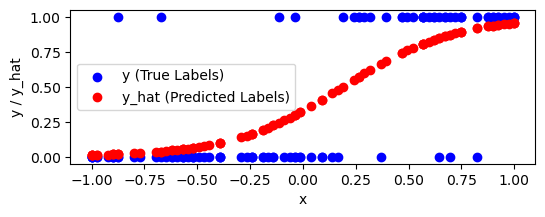

In [11]:

plt.figure(figsize=(6, 2))
plt.scatter(x, y, color='blue', label='y (True Labels)')
plt.scatter(x, y_hat, color='red', label='y_hat (Predicted Labels)')
plt.xlabel('x')
plt.ylabel('y / y_hat')
plt.legend()
plt.show()

## 8. Testing on 2D data


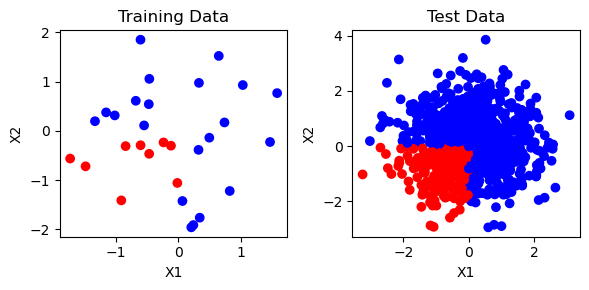

In [12]:
# Generate 2d data: one quarter is 1, the rest is 0
# These data are not linearly separable, so it is not expected that the logistic regression will perform well on this dataset.
np.random.seed(42)
X_train = np.random.randn(30, 2)
X_test = np.random.randn(1000, 2)
# make y a column vector (2D array) to match the shape of X with values if x1 + x2 > 0 then 1 else 0
y_train = ((X_train[:, 0] < 0) & (X_train[:, 1] < 0)).astype(int).reshape(-1, 1)
y_test = ((X_test[:, 0] < 0) & (X_test[:, 1] < 0)).astype(int).reshape(-1, 1)

# scatter plot the two datasets side by side
plt.figure(figsize=(6, 3))

plt.subplot(1, 2, 1)
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train.ravel(), cmap='bwr')
plt.title('Training Data')
plt.xlabel('X1')
plt.ylabel('X2')

plt.subplot(1, 2, 2)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test.ravel(), cmap='bwr')
plt.title('Test Data')
plt.xlabel('X1')
plt.ylabel('X2')

plt.tight_layout()
plt.show()


In [13]:
# Initialize and fit the model
my_model = LogisticRegression(verbose=True)
my_model.fit(X_train, y_train)
# Make predictions
y_hat = my_model.predict(X_test)


Epoch 0, Loss: 20.724
Epoch 100, Loss: 8.059
Epoch 200, Loss: 8.059
Epoch 300, Loss: 6.908
Epoch 400, Loss: 6.908
Epoch 500, Loss: 6.908
Epoch 600, Loss: 6.908
Epoch 700, Loss: 6.908
Epoch 800, Loss: 6.908
Epoch 900, Loss: 6.908


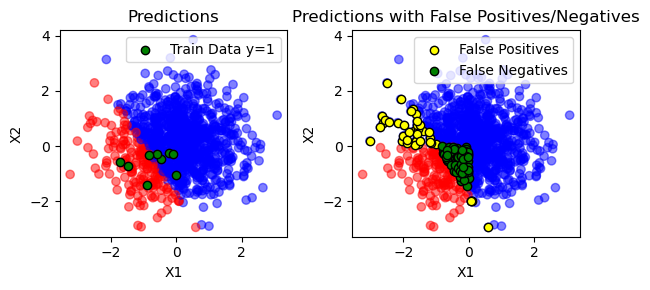

In [14]:
# Plot the results and compare it with training data and ground truth
plt.figure(figsize=(6, 3))

# Left plot: Predictions
plt.subplot(1, 2, 1)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_hat.ravel(), cmap='bwr', alpha=0.5)
plt.scatter(X_train[y_train[:, 0] == 1][:, 0], X_train[y_train[:, 0] == 1][:, 1], color='green', edgecolor='black', label='Train Data y=1')
plt.title('Predictions')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()

# Right plot: Predictions highlighting false positives and false negatives
plt.subplot(1, 2, 2)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test.ravel(), cmap='bwr', alpha=0.5)
fp = (y_test == 0) & (y_hat == 1)
fn = (y_test == 1) & (y_hat == 0)
plt.scatter(X_test[fp[:, 0], 0], X_test[fp[:, 0], 1], color='yellow', edgecolor='black', label='False Positives')
plt.scatter(X_test[fn[:, 0], 0], X_test[fn[:, 0], 1], color='green', edgecolor='black', label='False Negatives')
plt.title('Predictions with False Positives/Negatives')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()

plt.tight_layout()
plt.show()

## 9. Ideas to Deepen Your Knowledge
- Compare the performance of our implementation of logistic regression to the one in SciKit-Learn.
- Use real datasets.
- Add the scaling/normalization of the input space in the fit function.
- Include L1 and/or L2 regularization.
- Implement the support for mini-batch stochastic gradient descent